<a href="https://colab.research.google.com/github/carotorresoliva/tongoy-variabilidad-ambiental-fair/blob/main/Tongoy_variabilidad_ambiental_FAIR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Variabilidad espacial y estacional de las condiciones ambientales en Bahía Barnes, Tongoy

### Análisis mediante percepción remota y principios FAIR

##1. Introducción

Las condiciones ambientales de los ecosistemas amrinos costeros presentan variaciones espaciales y temporales que pueden influir en los procesos ecológicos y fisiológicos de los organismos marinos.

La percepción remota permite explorar estas variaciones mediante observaciones satelitales y herramientas de análisis geoespacial.

##2. Objetivo

Caracterizar exploratoriamente la variabilidad espacial y estacional de las condiciones ambientales en cinco puntos de Bahía Barnes, Tongoy, Chile, mediante productos satelitales.

##3. Fuentes de información

**Sentinel-2:** indicadores espectrales y reflectancia,

**MODIS Aqua:** temperatura superficial del mar (SST)

**Landsat 8/9:** información térmica complementaria.

##4. Reproducibilidad y principios FAIR

El procesamiento se desarrollará en Python mediante Google Colab. Se documentarán las fuentes, los períodos analizados, las variables, las unidades, los procedimientos de control de calidad y los metadatos necesarios para facilitar la reutilización de los datos.

##5. Configuración del entorno de trabajo

En esta sección se preparan las bibliotecas y herramientas necesarias para el procesamiento de datos satelitales de Python.

Se incorporan funciones del repositorio Geomática aplicada, utilizadas durante el taller, para favorecer la reproducibilidad del análisis y documental la procedencial del código.

In [7]:
%pip install -q rioxarray

In [8]:
# Clonar el repositorio del taller
!git clone https://github.com/alvaroparedesl/geomatica-aplicada.git

# Incorporar sus módulos al entorno de Python
import sys
sys.path.insert(0, "/content/geomatica-aplicada")

# Comprobar que podemos acceder a las funciones
from utils.raster import convertir_a_temperatura
from utils.series import construir_series_landsat

print("Repositorio conectado correctamente")

fatal: destination path 'geomatica-aplicada' already exists and is not an empty directory.
Repositorio conectado correctamente


### Definir área de estudio

In [9]:
# Definir los cinco puntos de estudio de Bahía Barnes, Tongoy
import pandas as pd

puntos_tongoy = pd.DataFrame({
    "id": [
        "tongoy_01", "tongoy_02", "tongoy_03",
        "tongoy_04", "tongoy_05"
    ],
    "nombre": [
        "Bahía Barnes - punto 01",
        "Bahía Barnes - punto 02",
        "Bahía Barnes - punto 03",
        "Bahía Barnes - punto 04",
        "Bahía Barnes - punto 05"
    ],
    "tipo": ["bahia"] * 5,
    "lon": [
        -71.508306, -71.486107, -71.499159,
        -71.484797, -71.505612
    ],
    "lat": [
        -30.251089, -30.248027, -30.246536,
        -30.241626, -30.244821
    ]
})

print("Puntos de estudio:", len(puntos_tongoy))
display(puntos_tongoy)

Puntos de estudio: 5


,id,nombre,tipo,lon,lat
0,tongoy_01,Bahía Barnes - punto 01,bahia,-71.508306,-30.251089
1,tongoy_02,Bahía Barnes - punto 02,bahia,-71.486107,-30.248027
2,tongoy_03,Bahía Barnes - punto 03,bahia,-71.499159,-30.246536
3,tongoy_04,Bahía Barnes - punto 04,bahia,-71.484797,-30.241626
4,tongoy_05,Bahía Barnes - punto 05,bahia,-71.505612,-30.244821


### Cobertura temporal y calidad de datos — Verano 2025–2026

In [10]:
# Cargar Sentinel-2 desde el repositorio público de GitHub

import pandas as pd

url_sentinel = (
    "https://raw.githubusercontent.com/"
    "carotorresoliva/tongoy-variabilidad-ambiental-fair/"
    "main/resultados_tongoy/sentinel2_tongoy_estacional.parquet"
)

sentinel_tongoy = pd.read_parquet(url_sentinel)

print("Registros Sentinel-2:", len(sentinel_tongoy))

Registros Sentinel-2: 375


In [11]:
# Revisar cobertura temporal y datos válidos de Sentinel-2
# Verano 2025–2026

datos_verano = sentinel_tongoy[
    sentinel_tongoy["estacion"] == "Verano"
].copy()

datos_verano["fecha"] = pd.to_datetime(datos_verano["fecha"])

print("Primera fecha:", datos_verano["fecha"].min().date())
print("Última fecha:", datos_verano["fecha"].max().date())
print("Fechas únicas:", datos_verano["fecha"].dt.normalize().nunique())

print("\nObservaciones válidas por punto:")

resumen_verano = (
    datos_verano
    .groupby("id")[["ndci", "ndwi", "b04", "ndvi"]]
    .count()
)

display(resumen_verano)

Primera fecha: 2025-12-01
Última fecha: 2026-02-26
Fechas únicas: 38

Observaciones válidas por punto:


,ndci,ndwi,b04,ndvi
id,,,,
tongoy_01,21,21,21,21
tongoy_02,21,21,21,21
tongoy_03,20,20,20,20
tongoy_04,20,20,20,20
tongoy_05,22,22,22,22


### Cobertura temporal y calidad de datos — Invierno 2026

In [12]:

datos_invierno = sentinel_tongoy[
    sentinel_tongoy["estacion"] == "Invierno"
].copy()

datos_invierno["fecha"] = pd.to_datetime(datos_invierno["fecha"])

print("Primera fecha:", datos_invierno["fecha"].min().date())
print("Última fecha:", datos_invierno["fecha"].max().date())
print("Fechas únicas:", datos_invierno["fecha"].dt.normalize().nunique())

print("\nObservaciones válidas por punto:")

resumen_invierno = (
    datos_invierno
    .groupby("id")[["ndci", "ndwi", "b04", "ndvi"]]
    .count()
)

display(resumen_invierno)

Primera fecha: 2026-06-01
Última fecha: 2026-08-30
Fechas únicas: 37

Observaciones válidas por punto:


,ndci,ndwi,b04,ndvi
id,,,,
tongoy_01,13,13,13,13
tongoy_02,6,7,10,5
tongoy_03,10,13,11,10
tongoy_04,8,10,11,10
tongoy_05,8,10,13,10


## Resumen espacial y estacional


In [13]:
# Comparación del NDCI entre puntos y estaciones

resumen_ndci = (
    sentinel_tongoy
    .groupby(["id", "estacion"])["ndci"]
    .agg(
        n="count",
        mediana="median",
        minimo="min",
        maximo="max"
    )
    .round(3)
)

display(resumen_ndci)

n  mediana  minimo  maximo
id        estacion                             
tongoy_01 Invierno  13   -0.147  -0.355   0.093
          Verano    21   -0.018  -0.086   0.021
tongoy_02 Invierno   6   -0.640  -0.750   0.059
          Verano    21   -0.043  -0.175   0.717
tongoy_03 Invierno  10   -0.446  -0.684   0.282
          Verano    20   -0.029  -0.088   0.460
tongoy_04 Invierno   8   -0.405  -0.750  -0.105
          Verano    20   -0.048  -0.134   0.020
tongoy_05 Invierno   8   -0.375  -0.714  -0.056
          Verano    22   -0.034  -0.132   0.543

**Interpretación de resultados (preliminar)**

Los cinco puntos de Bahía Barnes presentaron medianas de NDCI más negativas durante el invierno de 2026 respecto del verano 2025–2026. Sin embargo, la disponibilidad desigual de observaciones válidas entre estaciones, junto con posibles incertidumbres radiométricas, limita la interpretación ambiental de estas diferencias. Por lo tanto, los resultados se consideran descriptivos y no permiten atribuir directamente las variaciones del índice a cambios en la concentración de clorofila.

In [14]:
# Revisar NDCI y reflectancia roja (B04) por estación

revision_optica = (
    sentinel_tongoy
    .groupby(["estacion", "id"])
    .agg(
        n_ndci=("ndci", "count"),
        mediana_ndci=("ndci", "median"),
        mediana_b04=("b04", "median"),
        minimo_b04=("b04", "min")
    )
    .round(4)
)

display(revision_optica)

n_ndci  mediana_ndci  mediana_b04  minimo_b04
estacion id                                                      
Invierno tongoy_01      13       -0.1465       0.0040      0.0018
         tongoy_02       6       -0.6402       0.0006      0.0002
         tongoy_03      10       -0.4456       0.0015      0.0004
         tongoy_04       8       -0.4048       0.0014      0.0002
         tongoy_05       8       -0.3749       0.0009      0.0001
Verano   tongoy_01      21       -0.0181       0.0252      0.0085
         tongoy_02      21       -0.0425       0.0160      0.0016
         tongoy_03      20       -0.0293       0.0176      0.0030
         tongoy_04      20       -0.0477       0.0187      0.0066
         tongoy_05      22       -0.0342       0.0203      0.0019

**Interpretación de resultados (preliminar)**

La revisión de la reflectancia en la banda roja (B04) mostró medianas inferiores durante el invierno de 2026 en los cinco puntos de Bahía Barnes, coincidiendo con valores de NDCI más negativos respecto del verano 2025–2026. Esta correspondencia sugiere que las diferencias observadas en el índice deben evaluarse considerando el comportamiento radiométrico de las bandas utilizadas en su cálculo. No obstante, estos resultados descriptivos no permiten establecer las causas de las diferencias estacionales ni atribuirlas directamente a cambios en la concentración de clorofila.

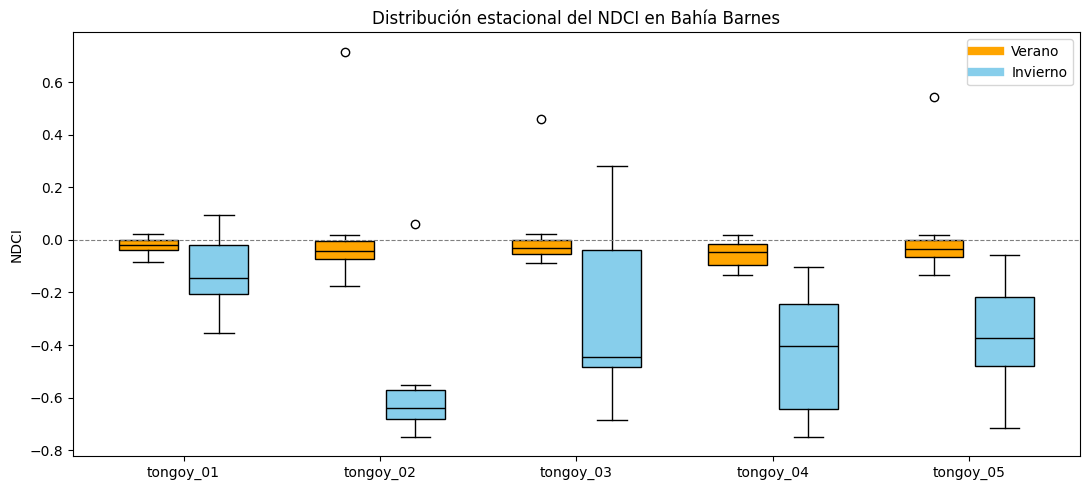

In [15]:
# Distribución del NDCI por punto y estación

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 5))

puntos = sorted(sentinel_tongoy["id"].unique())
posiciones = range(len(puntos))

for i, estacion in enumerate(["Verano", "Invierno"]):
    datos = [
        sentinel_tongoy.loc[
            (sentinel_tongoy["id"] == punto) &
            (sentinel_tongoy["estacion"] == estacion),
            "ndci"
        ].dropna()
        for punto in puntos
    ]

    desplazamiento = -0.18 if estacion == "Verano" else 0.18

    ax.boxplot(
        datos,
        positions=[p + desplazamiento for p in posiciones],
        widths=0.3,
        patch_artist=True,
        boxprops={
            "facecolor": "orange" if estacion == "Verano" else "skyblue"
        },
        medianprops={"color": "black"},
        manage_ticks=False
    )

ax.set_xticks(list(posiciones))
ax.set_xticklabels(puntos)
ax.set_ylabel("NDCI")
ax.set_title("Distribución estacional del NDCI en Bahía Barnes")
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)

ax.plot([], [], color="orange", linewidth=6, label="Verano")
ax.plot([], [], color="skyblue", linewidth=6, label="Invierno")
ax.legend()

plt.tight_layout()
plt.show()

### Interpretación de resultados: variabilidad espacial y estacional del NDCI

El análisis exploratorio mostró diferencias en la distribución del Índice de Diferencia Normalizada de Clorofila (NDCI) entre el verano 2025–2026 y el invierno 2026 en los cinco puntos de Bahía Barnes, Tongoy.

Durante el verano, las medianas se mantuvieron próximas a cero (−0,048 a −0,018), con presencia de valores atípicos positivos en algunos puntos. En contraste, durante el invierno se observaron medianas más negativas (−0,640 a −0,147) y diferencias en la dispersión de los valores entre puntos.

**Consideraciones metodológicas:** La disponibilidad de observaciones válidas fue menor durante el invierno (6–13 registros por punto) respecto del verano (20–22 registros por punto). Adicionalmente, las menores reflectancias de B04 registradas en invierno justifican revisar el comportamiento de las bandas espectrales utilizadas en el cálculo del índice y las posibles incertidumbres asociadas.

Por lo tanto, las diferencias identificadas se interpretan como variaciones espectrales exploratorias y no como evidencia directa de cambios en la concentración de clorofila-a. Se requiere una evaluación adicional de la calidad radiométrica para sustentar interpretaciones biofísicas.

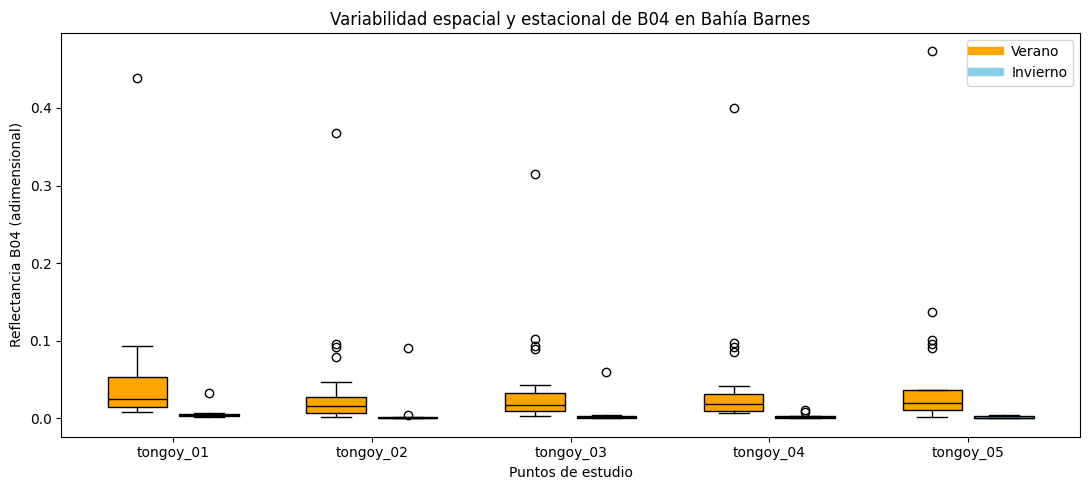

In [16]:
# Distribución espacial y estacional de la reflectancia B04

import matplotlib.pyplot as plt

puntos = sorted(sentinel_tongoy["id"].unique())
estaciones = ["Verano", "Invierno"]

fig, ax = plt.subplots(figsize=(11, 5))

for i, estacion in enumerate(estaciones):

    datos = [
        sentinel_tongoy.loc[
            (sentinel_tongoy["id"] == punto) &
            (sentinel_tongoy["estacion"] == estacion),
            "b04"
        ].dropna()
        for punto in puntos
    ]

    desplazamiento = -0.18 if estacion == "Verano" else 0.18

    ax.boxplot(
        datos,
        positions=[p + desplazamiento for p in range(len(puntos))],
        widths=0.3,
        patch_artist=True,
        boxprops={
            "facecolor": "orange" if estacion == "Verano" else "skyblue"
        },
        medianprops={"color": "black"},
        manage_ticks=False
    )

ax.set_xticks(range(len(puntos)))
ax.set_xticklabels(puntos)

ax.set_ylabel("Reflectancia B04 (adimensional)")
ax.set_xlabel("Puntos de estudio")
ax.set_title("Variabilidad espacial y estacional de B04 en Bahía Barnes")

ax.plot([], [], color="orange", linewidth=6, label="Verano")
ax.plot([], [], color="skyblue", linewidth=6, label="Invierno")
ax.legend()

plt.tight_layout()
plt.show()

### Interpretación de resultados: variabilidad espacial y estacional de la reflectancia B04

La reflectancia de la banda roja (B04) de Sentinel-2 presentó diferencias descriptivas entre el verano 2025–2026 y el invierno 2026 en los cinco puntos evaluados de Bahía Barnes, Tongoy.

Durante el verano se registraron medianas superiores (0,0160–0,0252) respecto del invierno (0,0006–0,0040). Las distribuciones estivales también presentaron valores elevados respecto de sus respectivas medianas, mientras que las reflectancias invernales se concentraron en magnitudes próximas a cero.

Este comportamiento es relevante para la interpretación de índices espectrales como el NDCI, cuyo cálculo involucra la reflectancia roja y otra banda espectral. Cuando las reflectancias utilizadas son muy pequeñas, las incertidumbres radiométricas pueden tener mayor influencia relativa sobre el valor calculado.

**Consideraciones metodológicas:** Las diferencias observadas podrían estar asociadas con variaciones en las propiedades ópticas del agua, pero también con condiciones atmosféricas, efectos costeros o limitaciones del procesamiento radiométrico. Los resultados son exploratorios y no permiten atribuir directamente las variaciones de B04 a cambios en la concentración de clorofila-a, turbidez u otros componentes del agua.

Se recomienda examinar la calidad radiométrica de las observaciones, especialmente aquellas con valores extremos, antes de realizar interpretaciones ambientales más específicas.

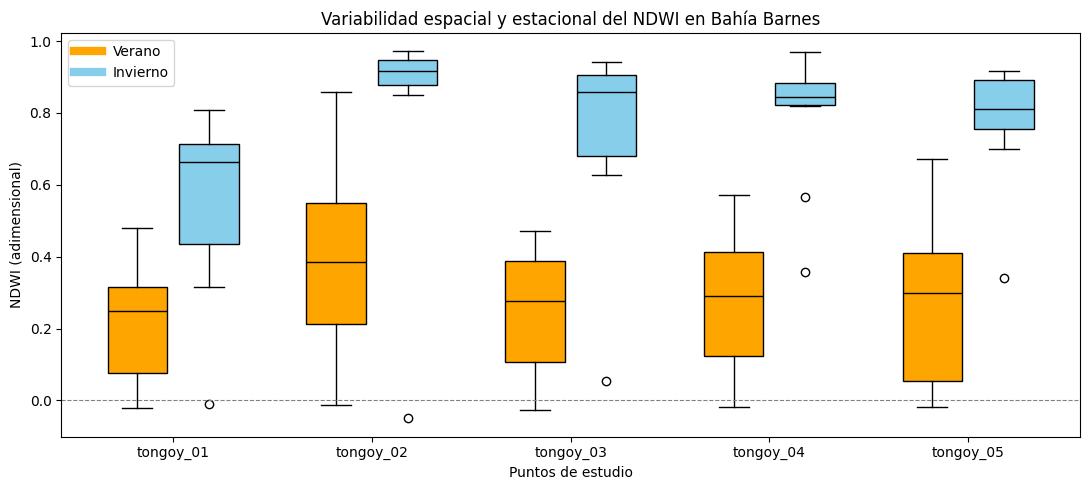

In [17]:
# Distribución espacial y estacional del NDWI en Bahía Barnes

import matplotlib.pyplot as plt

puntos = sorted(sentinel_tongoy["id"].unique())

fig, ax = plt.subplots(figsize=(11, 5))

for estacion, desplazamiento, color in [
    ("Verano", -0.18, "orange"),
    ("Invierno", 0.18, "skyblue")
]:
    datos = [
        sentinel_tongoy.loc[
            (sentinel_tongoy["id"] == punto) &
            (sentinel_tongoy["estacion"] == estacion),
            "ndwi"
        ].dropna()
        for punto in puntos
    ]

    ax.boxplot(
        datos,
        positions=[i + desplazamiento for i in range(len(puntos))],
        widths=0.3,
        patch_artist=True,
        boxprops={"facecolor": color},
        medianprops={"color": "black"},
        manage_ticks=False
    )

ax.set_xticks(range(len(puntos)))
ax.set_xticklabels(puntos)
ax.set_xlabel("Puntos de estudio")
ax.set_ylabel("NDWI (adimensional)")
ax.set_title("Variabilidad espacial y estacional del NDWI en Bahía Barnes")
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)

ax.plot([], [], color="orange", linewidth=6, label="Verano")
ax.plot([], [], color="skyblue", linewidth=6, label="Invierno")
ax.legend()

plt.tight_layout()
plt.show()

### Interpretación de resultados: variabilidad espacial y estacional del NDWI

El índice denominado NDWI en el procesamiento utilizado presentó diferencias descriptivas entre el verano 2025–2026 y el invierno 2026 en los cinco puntos de Bahía Barnes, Tongoy.

Durante el invierno se observaron medianas superiores a las registradas en verano. El punto 02 presentó una de las medianas invernales más elevadas, mientras que las distribuciones estivales mostraron diferencias en su dispersión entre puntos.

Estos resultados describen variaciones en la respuesta espectral de los píxeles analizados entre ambas estaciones. Sin embargo, su interpretación depende de la formulación del índice, la calidad radiométrica de las observaciones y las características de los píxeles costeros.

**Aclaración metodológica sobre el NDWI**

La función utilizada calcula el índice mediante la expresión NDWI = (NIR − SWIR1) / (NIR + SWIR1), empleando las bandas B08 y B11 de Sentinel-2. Esta formulación, también conocida como NDWI de Gao o NDMI, se utiliza principalmente para estudiar el contenido de agua en vegetación y otras superficies terrestres.

En ambientes marinos costeros, su aplicación requiere especial precaución, debido a las características espectrales del agua y a la posible influencia de píxeles mixtos y efectos costeros.

En consecuencia, las diferencias entre verano e invierno se consideran variaciones espectrales exploratorias y no constituyen evidencia directa de cambios en propiedades oceanográficas del agua.

## Temperatura superficial del mar (SST): MODIS Aqua

Se analizaron datos de temperatura superficial del mar (SST) obtenidos mediante el sensor MODIS a bordo del satélite Aqua, con el propósito de caracterizar descriptivamente la variabilidad térmica entre el verano 2025–2026 y el invierno 2026 en Bahía Barnes, Tongoy.

Se utilizó el producto satelital mensual de temperatura superficial del mar MODIS Aqua L3 SST Thermal Daytime, distribuido por la NASA, con una resolución espacial nominal de 4 km. Se consideraron los meses de diciembre de 2025, enero y febrero de 2026, y junio, julio y agosto de 2026.

Debido a la resolución espacial del producto, los cinco puntos de estudio no correspondieron a cinco observaciones espaciales independientes: algunos compartieron el mismo píxel satelital. Por ello, se identificaron los píxeles únicos y se utilizaron sus valores de SST para construir resúmenes mensuales, evitando contabilizar repetidamente una misma observación espacial.

Los resultados permiten describir diferencias térmicas entre los períodos estudiados, sin representar la variabilidad a escalas espaciales inferiores a la resolución del producto ni establecer tendencias climáticas de largo plazo.

In [18]:
# Instalar biblioteca para acceder a datos de la NASA
%pip install -q earthaccess

In [19]:
# Verificar la instalación de earthaccess

import earthaccess

print("earthaccess importado correctamente")

earthaccess importado correctamente


In [20]:
# Buscar el producto MODIS Aqua SST de 4 km

import earthaccess

productos_modis = earthaccess.search_datasets(
    keyword="MODIS Aqua SST 4km Level 3"
)

print("Productos encontrados:", len(productos_modis))

for producto in productos_modis[:10]:
    print(
        producto.get("umm", {}).get("ShortName"),
        "|",
        producto.get("umm", {}).get("EntryTitle")
    )

Productos encontrados: 12
MODIS_AQUA_L3_SST_THERMAL_8DAY_4KM_DAYTIME_V2019.0 | MODIS Aqua Level 3 SST Thermal IR 8 Day 4km Daytime V2019.0
MODIS_AQUA_L3_SST_MID-IR_8DAY_4KM_NIGHTTIME_V2019.0 | MODIS Aqua Level 3 SST MID-IR 8 Day 4km Nighttime V2019.0
MODIS_AQUA_L3_SST_MID-IR_ANNUAL_4KM_NIGHTTIME_V2019.0 | MODIS Aqua Level 3 SST MID-IR Annual 4km Nighttime V2019.0
MODIS_AQUA_L3_SST_MID-IR_DAILY_4KM_NIGHTTIME_V2019.0 | MODIS Aqua Level 3 SST MID-IR Daily 4km Nighttime V2019.0
MODIS_AQUA_L3_SST_MID-IR_MONTHLY_4KM_NIGHTTIME_V2019.0 | MODIS Aqua Level 3 SST MID-IR Monthly 4km Nighttime V2019.0
MODIS_AQUA_L3_SST_THERMAL_8DAY_4KM_NIGHTTIME_V2019.0 | MODIS Aqua Level 3 SST Thermal IR 8 Day 4km Nighttime V2019.0
MODIS_AQUA_L3_SST_THERMAL_ANNUAL_4KM_DAYTIME_V2019.0 | MODIS Aqua Level 3 SST Thermal IR Annual 4km Daytime V2019.0
MODIS_AQUA_L3_SST_THERMAL_ANNUAL_4KM_NIGHTTIME_V2019.0 | MODIS Aqua Level 3 SST Thermal IR Annual 4km Nighttime V2019.0
MODIS_AQUA_L3_SST_THERMAL_DAILY_4KM_DAYTIME_V2019.0

In [21]:
# Identificar productos mensuales de SST MODIS Aqua

for producto in productos_modis:
    nombre = producto.get("umm", {}).get("ShortName", "")

    if "MONTHLY" in nombre:
        print(nombre)

MODIS_AQUA_L3_SST_MID-IR_MONTHLY_4KM_NIGHTTIME_V2019.0
MODIS_AQUA_L3_SST_THERMAL_MONTHLY_4KM_DAYTIME_V2019.0
MODIS_AQUA_L3_SST_THERMAL_MONTHLY_4KM_NIGHTTIME_V2019.0


In [22]:
# Seleccionar el producto mensual de SST MODIS Aqua

producto_sst = "MODIS_AQUA_L3_SST_THERMAL_MONTHLY_4KM_DAYTIME_V2019.0"

# Buscar los meses de nuestro período de estudio
granulos_sst = earthaccess.search_data(
    short_name=producto_sst,
    temporal=("2025-12-01", "2026-08-31")
)

print("Archivos encontrados:", len(granulos_sst))

for granulo in granulos_sst[:10]:
    print(granulo["meta"].get("native-id"))

Archivos encontrados: 20
AQUA_MODIS.20251101_20251130.L3m.MO.SST.sst.4km.NRT
AQUA_MODIS.20251101_20251130.L3m.MO.SST.sst.4km
AQUA_MODIS.20251201_20251231.L3m.MO.SST.sst.4km.NRT
AQUA_MODIS.20251201_20251231.L3m.MO.SST.sst.4km
AQUA_MODIS.20260101_20260131.L3m.MO.SST.sst.4km
AQUA_MODIS.20260101_20260131.L3m.MO.SST.sst.4km.NRT
AQUA_MODIS.20260201_20260228.L3m.MO.SST.sst.4km.NRT
AQUA_MODIS.20260201_20260228.L3m.MO.SST.sst.4km
AQUA_MODIS.20260301_20260331.L3m.MO.SST.sst.4km.NRT
AQUA_MODIS.20260301_20260331.L3m.MO.SST.sst.4km


In [23]:
# Revisar los archivos mensuales MODIS Aqua sin etiqueta NRT

granulos_finales = [
    g for g in granulos_sst
    if ".NRT" not in g["meta"].get("native-id", "").upper()
]

print("Archivos sin NRT:", len(granulos_finales))

for g in granulos_finales:
    print(g["meta"].get("native-id"))

Archivos sin NRT: 10
AQUA_MODIS.20251101_20251130.L3m.MO.SST.sst.4km
AQUA_MODIS.20251201_20251231.L3m.MO.SST.sst.4km
AQUA_MODIS.20260101_20260131.L3m.MO.SST.sst.4km
AQUA_MODIS.20260201_20260228.L3m.MO.SST.sst.4km
AQUA_MODIS.20260301_20260331.L3m.MO.SST.sst.4km
AQUA_MODIS.20260401_20260430.L3m.MO.SST.sst.4km
AQUA_MODIS.20260501_20260531.L3m.MO.SST.sst.4km
AQUA_MODIS.20260601_20260630.L3m.MO.SST.sst.4km
AQUA_MODIS.20260701_20260731.L3m.MO.SST.sst.4km
AQUA_MODIS.20260801_20260831.L3m.MO.SST.sst.4km


In [24]:
# Seleccionar los meses de verano e invierno

meses_estudio = [
    "202512", "202601", "202602",
    "202606", "202607", "202608"
]

granulos_estudio = [
    g for g in granulos_finales
    if g["meta"]["native-id"].split(".")[1][:6] in meses_estudio
]

print("Archivos seleccionados:", len(granulos_estudio))

for g in granulos_estudio:
    print(g["meta"]["native-id"])

Archivos seleccionados: 6
AQUA_MODIS.20251201_20251231.L3m.MO.SST.sst.4km
AQUA_MODIS.20260101_20260131.L3m.MO.SST.sst.4km
AQUA_MODIS.20260201_20260228.L3m.MO.SST.sst.4km
AQUA_MODIS.20260601_20260630.L3m.MO.SST.sst.4km
AQUA_MODIS.20260701_20260731.L3m.MO.SST.sst.4km
AQUA_MODIS.20260801_20260831.L3m.MO.SST.sst.4km


In [25]:
# Autenticación para acceder a datos NASA Earthdata

import earthaccess

auth = earthaccess.login(strategy="interactive")

print("Autenticación exitosa:", auth.authenticated)

Enter your Earthdata Login username: carotorresoliva
Enter your Earthdata password: ··········
Autenticación exitosa: True


In [26]:
# Definir carpeta para almacenar archivos MODIS Aqua

from pathlib import Path

carpeta_modis = Path("/content/modis_aqua")
carpeta_modis.mkdir(parents=True, exist_ok=True)

print("Carpeta MODIS:", carpeta_modis)

Carpeta MODIS: /content/modis_aqua


In [27]:
# Descargar los seis meses seleccionados de MODIS Aqua
# Verano 2025–2026 e invierno 2026

archivos_descargados = earthaccess.download(
    granulos_estudio,
    local_path=str(carpeta_modis)
)

print("Archivos disponibles:", len(archivos_descargados))

for archivo in archivos_descargados:
    print(archivo)

QUEUEING TASKS | :   0%|          | 0/6 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/6 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/6 [00:00<?, ?it/s]

Archivos disponibles: 6
/content/modis_aqua/AQUA_MODIS.20251201_20251231.L3m.MO.SST.sst.4km.nc
/content/modis_aqua/AQUA_MODIS.20260101_20260131.L3m.MO.SST.sst.4km.nc
/content/modis_aqua/AQUA_MODIS.20260201_20260228.L3m.MO.SST.sst.4km.nc
/content/modis_aqua/AQUA_MODIS.20260601_20260630.L3m.MO.SST.sst.4km.nc
/content/modis_aqua/AQUA_MODIS.20260701_20260731.L3m.MO.SST.sst.4km.nc
/content/modis_aqua/AQUA_MODIS.20260801_20260831.L3m.MO.SST.sst.4km.nc


In [28]:
# Verificar los archivos mensuales de MODIS Aqua

from pathlib import Path
import re

archivos_modis = sorted([
    archivo
    for archivo in carpeta_modis.iterdir()
    if archivo.is_file()
    and re.search(r"AQUA_MODIS\.\d{8}_\d{8}", archivo.name)
])

print("Total de archivos:", len(archivos_modis))

for archivo in archivos_modis:
    fecha = re.search(r"AQUA_MODIS\.(\d{6})", archivo.name)
    print(fecha.group(1), "|", archivo.name)

assert len(archivos_modis) == 6, (
    "Revisar archivos faltantes o duplicados."
)

Total de archivos: 6
202512 | AQUA_MODIS.20251201_20251231.L3m.MO.SST.sst.4km.nc
202601 | AQUA_MODIS.20260101_20260131.L3m.MO.SST.sst.4km.nc
202602 | AQUA_MODIS.20260201_20260228.L3m.MO.SST.sst.4km.nc
202606 | AQUA_MODIS.20260601_20260630.L3m.MO.SST.sst.4km.nc
202607 | AQUA_MODIS.20260701_20260731.L3m.MO.SST.sst.4km.nc
202608 | AQUA_MODIS.20260801_20260831.L3m.MO.SST.sst.4km.nc


In [29]:
# Abrir un archivo MODIS Aqua para revisar sus metadatos

import xarray as xr

ds_modis = xr.open_dataset(archivos_modis[0])

print("Archivo abierto:", archivos_modis[0].name)
print("Variables disponibles:", list(ds_modis.data_vars))

Archivo abierto: AQUA_MODIS.20251201_20251231.L3m.MO.SST.sst.4km.nc
Variables disponibles: ['sst', 'qual_sst', 'palette']


In [30]:
# Revisar unidades y atributos de las variables MODIS Aqua

print("METADATOS DE SST")
print(ds_modis["sst"].attrs)

print("\nMETADATOS DE CALIDAD")
print(ds_modis["qual_sst"].attrs)

METADATOS DE SST
{'long_name': 'Sea Surface Temperature', 'units': 'degree_C', 'standard_name': 'sea_surface_temperature', 'valid_min': np.int16(-1000), 'valid_max': np.int16(10000), 'display_scale': 'linear', 'display_min': np.float32(-2.0), 'display_max': np.float32(45.0)}

METADATOS DE CALIDAD
{'long_name': 'Quality Levels, Sea Surface Temperature', 'valid_min': np.uint8(0), 'valid_max': np.uint8(5)}


In [31]:
# Seleccionar una región alrededor de Bahía Barnes, Tongoy
# MODIS Aqua - diciembre de 2025

modis_tongoy = ds_modis[["sst", "qual_sst"]].sel(
    lat=slice(-30.10, -30.40),
    lon=slice(-71.70, -71.30)
)

print("Dimensiones de la región:")
print(modis_tongoy.sizes)

print("\nValores de SST disponibles:")
print(modis_tongoy["sst"].count().item())

print("\nCódigos de calidad presentes:")
print(
    modis_tongoy["qual_sst"]
    .to_series()
    .value_counts(dropna=False)
    .sort_index()
)

Dimensiones de la región:
Frozen({'lat': 8, 'lon': 10})

Valores de SST disponibles:
48

Códigos de calidad presentes:
qual_sst
0.0    47
1.0     1
NaN    32
Name: count, dtype: int64


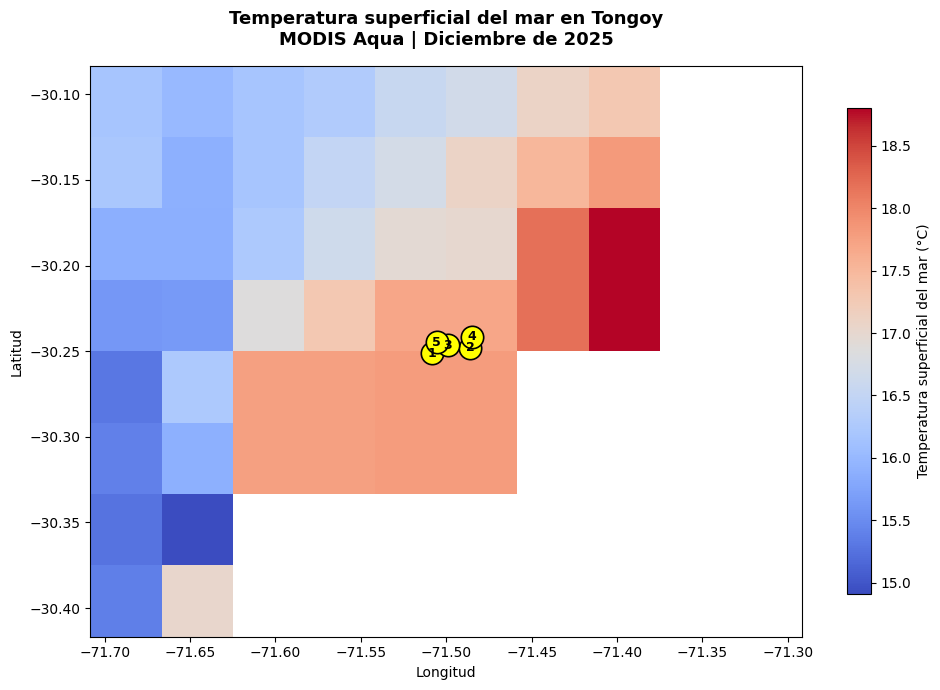

In [32]:
# Mapa de SST MODIS Aqua en Tongoy
# Visualización de los cinco puntos de Bahía Barnes

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 7))

# Temperatura superficial del mar
im = modis_tongoy["sst"].plot(
    ax=ax,
    cmap="coolwarm",
    add_colorbar=False
)

# Puntos de estudio
ax.scatter(
    puntos_tongoy["lon"],
    puntos_tongoy["lat"],
    s=260,
    color="yellow",
    edgecolor="black",
    linewidth=1.2,
    zorder=5
)

# Números dentro de los círculos
for i, punto in puntos_tongoy.iterrows():
    ax.text(
        punto["lon"],
        punto["lat"],
        str(i + 1),
        fontsize=9,
        fontweight="bold",
        color="black",
        ha="center",
        va="center",
        zorder=6
    )

# Barra de temperatura
cbar = plt.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label("Temperatura superficial del mar (°C)")

# Títulos
ax.set_title(
    "Temperatura superficial del mar en Tongoy\n"
    "MODIS Aqua | Diciembre de 2025",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

# Sin cuadrícula superpuesta
ax.grid(False)

plt.tight_layout()
plt.show()

In [33]:
# Comprobar qué píxel MODIS representa cada punto
# Diciembre de 2025

registros = []

for _, punto in puntos_tongoy.iterrows():

    pixel = modis_tongoy.sel(
        lat=punto["lat"],
        lon=punto["lon"],
        method="nearest"
    )

    registros.append({
        "punto": punto["id"],
        "lat_pixel": float(pixel["lat"].values),
        "lon_pixel": float(pixel["lon"].values),
        "sst_c": float(pixel["sst"].values),
        "calidad": float(pixel["qual_sst"].values)
    })

comparacion_pixeles = pd.DataFrame(registros)

display(comparacion_pixeles.round(4))

print(
    "Píxeles MODIS distintos:",
    comparacion_pixeles[["lat_pixel", "lon_pixel"]]
    .drop_duplicates()
    .shape[0]
)

,punto,lat_pixel,lon_pixel,sst_c,calidad
0,tongoy_01,-30.2708,-71.5208,17.8,0.0
1,tongoy_02,-30.2292,-71.4792,17.7,0.0
2,tongoy_03,-30.2292,-71.4792,17.7,0.0
3,tongoy_04,-30.2292,-71.4792,17.7,0.0
4,tongoy_05,-30.2292,-71.5208,17.7,0.0


Píxeles MODIS distintos: 3


### Interpretación espacial de la SST — diciembre de 2025

La extracción de temperatura superficial del mar (SST) mediante MODIS Aqua identificó tres píxeles satelitales distintos asociados a los cinco puntos de estudio de Bahía Barnes, Tongoy.

Los puntos 02, 03 y 04 compartieron un mismo píxel, mientras que los puntos 01 y 05 correspondieron a píxeles diferentes. Las estimaciones mensuales de SST oscilaron entre 17,7 y 17,8 °C, evidenciando una reducida diferencia térmica entre los tres píxeles seleccionados durante diciembre de 2025.

**Consideraciones metodológicas:** La resolución espacial nominal de 4 km limita la identificación de diferencias térmicas locales. Además, los puntos que comparten un píxel no constituyen observaciones espaciales independientes. Por lo tanto, la similitud de las temperaturas extraídas no demuestra homogeneidad térmica a escalas inferiores a la resolución del producto.

Estos resultados respaldan el uso exploratorio de MODIS Aqua para caracterizar el contexto térmico marino del área de estudio. Su interpretación debe considerar los criterios de calidad del producto y complementarse con la comparación temporal de los seis meses seleccionados.

In [34]:
# Extraer la SST mensual de MODIS Aqua para Bahía Barnes

import pandas as pd
import numpy as np
import xarray as xr
import re

registros_sst = []

for archivo in archivos_modis:

    # Identificar el mes a partir del nombre del archivo
    fecha = re.search(r"AQUA_MODIS\.(\d{8})", archivo.name)
    fecha = pd.to_datetime(fecha.group(1), format="%Y%m%d")

    estacion = "Verano" if fecha.month in [12, 1, 2] else "Invierno"

    with xr.open_dataset(archivo) as ds:

        for _, punto in puntos_tongoy.iterrows():

            pixel = ds[["sst", "qual_sst"]].sel(
                lat=punto["lat"],
                lon=punto["lon"],
                method="nearest"
            )

            registros_sst.append({
                "fecha": fecha,
                "estacion": estacion,
                "id": punto["id"],
                "lat_pixel": float(pixel["lat"].values),
                "lon_pixel": float(pixel["lon"].values),
                "sst_c": float(pixel["sst"].values),
                "qual_sst": float(pixel["qual_sst"].values)
            })

sst_tongoy = pd.DataFrame(registros_sst)

print("Registros extraídos:", len(sst_tongoy))

display(sst_tongoy.head(10))

Registros extraídos: 30


,fecha,estacion,id,lat_pixel,lon_pixel,sst_c,qual_sst
0,2025-12-01,Verano,tongoy_01,-30.270838,-71.520828,17.799999,0.0
1,2025-12-01,Verano,tongoy_02,-30.229170,-71.479164,17.699999,0.0
2,2025-12-01,Verano,tongoy_03,-30.229170,-71.479164,17.699999,0.0
3,2025-12-01,Verano,tongoy_04,-30.229170,-71.479164,17.699999,0.0
4,2025-12-01,Verano,tongoy_05,-30.229170,-71.520828,17.699999,0.0
5,2026-01-01,Verano,tongoy_01,-30.270838,-71.520828,19.299999,0.0
6,2026-01-01,Verano,tongoy_02,-30.229170,-71.479164,18.934999,0.0
7,2026-01-01,Verano,tongoy_03,-30.229170,-71.479164,18.934999,0.0
8,2026-01-01,Verano,tongoy_04,-30.229170,-71.479164,18.934999,0.0
9,2026-01-01,Verano,tongoy_05,-30.229170,-71.520828,18.934999,0.0


In [35]:
# Revisar SST mensual y calidad de los datos MODIS Aqua

tabla_sst = sst_tongoy.pivot(
    index="fecha",
    columns="id",
    values="sst_c"
)

print("Temperatura superficial del mar (°C):")
display(tabla_sst.round(2))

print("\nCódigos de calidad por mes y punto:")

tabla_calidad = sst_tongoy.pivot(
    index="fecha",
    columns="id",
    values="qual_sst"
)

display(tabla_calidad)

Temperatura superficial del mar (°C):


id,tongoy_01,tongoy_02,tongoy_03,tongoy_04,tongoy_05
fecha,,,,,
2025-12-01,17.80,17.70,17.70,17.70,17.70
2026-01-01,19.30,18.93,18.93,18.93,18.93
2026-02-01,19.30,19.02,19.02,19.02,19.02
2026-06-01,14.42,14.30,14.30,14.30,14.30
2026-07-01,14.40,14.24,14.24,14.24,14.24
2026-08-01,15.36,15.56,15.56,15.56,15.56



Códigos de calidad por mes y punto:


id,tongoy_01,tongoy_02,tongoy_03,tongoy_04,tongoy_05
fecha,,,,,
2025-12-01,0.0,0.0,0.0,0.0,0.0
2026-01-01,0.0,0.0,0.0,0.0,0.0
2026-02-01,0.0,0.0,0.0,0.0,0.0
2026-06-01,0.0,0.0,0.0,0.0,0.0
2026-07-01,0.0,0.0,0.0,0.0,0.0
2026-08-01,0.0,0.0,0.0,0.0,0.0


In [36]:
# Control de calidad de la SST MODIS Aqua

print("Códigos de calidad en los 30 registros:")
display(sst_tongoy["qual_sst"].value_counts(dropna=False))

# Conservar solamente datos de mejor calidad
sst_validada = sst_tongoy[
    (sst_tongoy["qual_sst"] == 0) &
    (sst_tongoy["sst_c"].notna())
].copy()

# Evitar contar varias veces el mismo píxel
sst_pixeles = sst_validada.drop_duplicates(
    subset=["fecha", "lat_pixel", "lon_pixel"]
).copy()

print("\nRegistros con calidad 0:", len(sst_validada))
print("Observaciones píxel-mes independientes:", len(sst_pixeles))

print("\nPíxeles distintos por mes:")
display(sst_pixeles.groupby("fecha").size())

Códigos de calidad en los 30 registros:


,count
qual_sst,
0.0,30



Registros con calidad 0: 30
Observaciones píxel-mes independientes: 18

Píxeles distintos por mes:


,0
fecha,
2025-12-01,3
2026-01-01,3
2026-02-01,3
2026-06-01,3
2026-07-01,3
2026-08-01,3


## Construcción de la serie temporal de Temperatura Superficial del Mar (SST)

In [37]:
# Resumir la SST mensual de Bahía Barnes
# Sin duplicar píxeles MODIS

resumen_sst = (
    sst_pixeles
    .groupby(["fecha", "estacion"])
    .agg(
        n_pixeles=("sst_c", "count"),
        sst_mediana=("sst_c", "median"),
        sst_minima=("sst_c", "min"),
        sst_maxima=("sst_c", "max")
    )
    .reset_index()
    .sort_values("fecha")
)

display(resumen_sst.round(2))

,fecha,estacion,n_pixeles,sst_mediana,sst_minima,sst_maxima
0,2025-12-01,Verano,3,17.70,17.70,17.80
1,2026-01-01,Verano,3,18.93,18.93,19.30
2,2026-02-01,Verano,3,19.02,19.02,19.30
3,2026-06-01,Invierno,3,14.30,14.30,14.42
4,2026-07-01,Invierno,3,14.24,14.24,14.40
5,2026-08-01,Invierno,3,15.56,15.36,15.56


##Gráfico temporal de **SST**

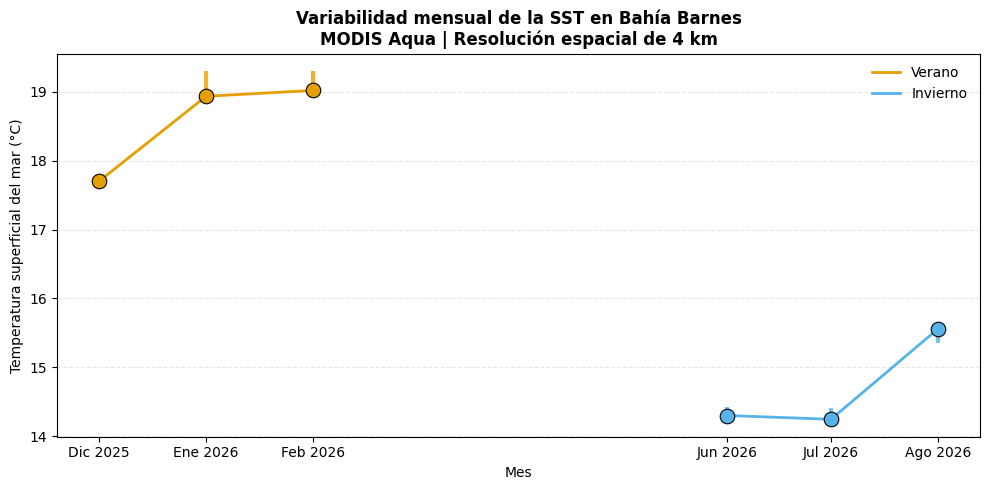

In [38]:
# Variabilidad mensual de la SST en Bahía Barnes
# MODIS Aqua: verano 2025-2026 e invierno 2026

import matplotlib.pyplot as plt
import pandas as pd

datos = resumen_sst.sort_values("fecha").copy()

colores = {
    "Verano": "#E69F00",
    "Invierno": "#56B4E9"
}

fig, ax = plt.subplots(figsize=(10, 5))

for _, fila in datos.iterrows():
    ax.scatter(
        fila["fecha"],
        fila["sst_mediana"],
        color=colores[fila["estacion"]],
        s=110,
        edgecolor="black",
        linewidth=0.8,
        zorder=3
    )

    ax.vlines(
        fila["fecha"],
        fila["sst_minima"],
        fila["sst_maxima"],
        color=colores[fila["estacion"]],
        linewidth=3,
        alpha=0.8
    )

# Unir los meses dentro de cada estación
for estacion in ["Verano", "Invierno"]:
    sub = datos[datos["estacion"] == estacion]

    ax.plot(
        sub["fecha"],
        sub["sst_mediana"],
        color=colores[estacion],
        linewidth=2,
        label=estacion
    )

# Etiquetas mensuales
ax.set_xticks(datos["fecha"])
ax.set_xticklabels(
    ["Dic 2025", "Ene 2026", "Feb 2026",
     "Jun 2026", "Jul 2026", "Ago 2026"]
)

ax.set_ylabel("Temperatura superficial del mar (°C)")
ax.set_xlabel("Mes")
ax.set_title(
    "Variabilidad mensual de la SST en Bahía Barnes\n"
    "MODIS Aqua | Resolución espacial de 4 km",
    fontweight="bold"
)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

### Interpretación de resultados: variabilidad temporal y estacional de la SST

La temperatura superficial del mar (SST), estimada mediante MODIS Aqua, presentó un contraste estacional entre el verano 2025–2026 y el invierno de 2026 en la región de Bahía Barnes, Tongoy.

Durante el verano, las medianas mensuales de SST variaron entre 17,70 y 19,02 °C, observándose un aumento desde diciembre hasta febrero. En invierno, las medianas fluctuaron entre 14,24 y 15,56 °C, registrándose el valor más bajo en julio y un incremento durante agosto.

Los tres píxeles MODIS seleccionados presentaron diferencias térmicas relativamente pequeñas dentro de cada mes, en comparación con las variaciones observadas entre estaciones.

**Consideraciones metodológicas:** Se utilizaron productos mensuales de SST MODIS Aqua de resolución espacial nominal de 4 km, conservando observaciones con código de calidad `qual_sst = 0`. Los cinco puntos de estudio estuvieron representados por tres píxeles distintos, evitando su duplicación en el cálculo de los resúmenes mensuales.

Debido a la resolución espacial del producto, los resultados caracterizan el contexto térmico marino de la zona, sin permitir evaluar adecuadamente la heterogeneidad térmica a escala local. Además, la comparación corresponde a seis meses seleccionados de un único período anual de estudio y no constituye una climatología histórica.

Las líneas verticales representan los valores mínimo y máximo de SST entre los píxeles seleccionados, no intervalos de confianza.

### Comparación estacional de la temperatura superficial del mar

In [39]:
# Comparación descriptiva de SST entre verano e invierno
# Se utilizan las medianas mensuales, sin duplicar píxeles MODIS

comparacion_estacional = (
    resumen_sst
    .groupby("estacion")
    .agg(
        n_meses=("sst_mediana", "count"),
        sst_media=("sst_mediana", "mean"),
        sst_mediana=("sst_mediana", "median"),
        sst_minima=("sst_mediana", "min"),
        sst_maxima=("sst_mediana", "max")
    )

)

display(comparacion_estacional.round(2))

# Diferencia entre las medias de las medianas mensuales
diferencia_sst = (
    comparacion_estacional.loc["Verano", "sst_media"]
    - comparacion_estacional.loc["Invierno", "sst_media"]
)

print(f"\nDiferencia estacional descriptiva: {diferencia_sst:.2f} °C")

,n_meses,sst_media,sst_mediana,sst_minima,sst_maxima
estacion,,,,,
Invierno,3,14.70,14.30,14.24,15.56
Verano,3,18.55,18.93,17.70,19.02



Diferencia estacional descriptiva: 3.85 °C


### Interpretación de resultados: contraste térmico estacional

El análisis de la temperatura superficial del mar (SST) mediante MODIS Aqua evidenció un contraste térmico entre el verano 2025–2026 y el invierno de 2026 en el sector estudiado de Bahía Barnes, Tongoy.

La media de las medianas mensuales de SST fue de **18,55 °C durante el verano** y **14,70 °C durante el invierno**, obteniéndose una diferencia descriptiva de **3,85 °C** entre ambas estaciones.

Estos resultados muestran que las condiciones térmicas superficiales fueron más cálidas durante los meses estivales seleccionados, lo que resulta relevante para caracterizar la variabilidad ambiental estacional de los ecosistemas marinos costeros.

**Consideraciones metodológicas:** Cada estación estuvo representada por tres meses. Los valores mensuales se calcularon a partir de tres píxeles MODIS distintos, con resolución espacial nominal de 4 km y código de calidad `qual_sst = 0`, evitando duplicar los puntos que compartían un mismo píxel.

La diferencia calculada es descriptiva y corresponde exclusivamente a los períodos analizados. No representa una climatología histórica y, dado que no se realizaron pruebas inferenciales, no permite establecer si la diferencia observada es estadísticamente significativa. Asimismo, la resolución espacial del producto limita la evaluación de la heterogeneidad térmica a escala local.

### Exportación de tablas a Parquet



In [40]:
# Guardar los datos procesados del estudio de Tongoy

from pathlib import Path

# Crear carpeta de resultados
carpeta_resultados = Path("/content/resultados_tongoy")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

# Sentinel-2: verano e invierno
sentinel_tongoy.to_parquet(
    carpeta_resultados / "sentinel2_tongoy_estacional.parquet",
    index=False
)

# MODIS Aqua: SST mensual por punto
sst_tongoy.to_parquet(
    carpeta_resultados / "modis_aqua_sst_puntos.parquet",
    index=False
)

# MODIS Aqua: SST por píxel único y mes
sst_pixeles.to_parquet(
    carpeta_resultados / "modis_aqua_sst_pixeles.parquet",
    index=False
)

# MODIS Aqua: resumen térmico mensual
resumen_sst.to_parquet(
    carpeta_resultados / "modis_aqua_sst_resumen_mensual.parquet",
    index=False
)

print("Archivos guardados correctamente:\n")

for archivo in sorted(carpeta_resultados.glob("*.parquet")):
    print(archivo.name, "-", round(archivo.stat().st_size / 1024, 1), "KB")

Archivos guardados correctamente:

modis_aqua_sst_pixeles.parquet - 4.6 KB
modis_aqua_sst_puntos.parquet - 4.6 KB
modis_aqua_sst_resumen_mensual.parquet - 4.2 KB
sentinel2_tongoy_estacional.parquet - 16.3 KB


### Preparación de metadatos

In [41]:
# Revisar la estructura de los archivos procesados
# Información necesaria para elaborar los metadatos FAIR

for archivo in sorted(carpeta_resultados.glob("*.parquet")):

    datos = pd.read_parquet(archivo)

    print(f"\nARCHIVO: {archivo.name}")
    print("Registros:", len(datos))
    print("Variables:", list(datos.columns))


ARCHIVO: modis_aqua_sst_pixeles.parquet
Registros: 18
Variables: ['fecha', 'estacion', 'id', 'lat_pixel', 'lon_pixel', 'sst_c', 'qual_sst']

ARCHIVO: modis_aqua_sst_puntos.parquet
Registros: 30
Variables: ['fecha', 'estacion', 'id', 'lat_pixel', 'lon_pixel', 'sst_c', 'qual_sst']

ARCHIVO: modis_aqua_sst_resumen_mensual.parquet
Registros: 6
Variables: ['fecha', 'estacion', 'n_pixeles', 'sst_mediana', 'sst_minima', 'sst_maxima']

ARCHIVO: sentinel2_tongoy_estacional.parquet
Registros: 375
Variables: ['id', 'nombre', 'tipo', 'lat', 'lon', 'fecha', 'ndwi', 'ndci', 'b04', 'ndvi', 'nubes_escena', 'pixeles_validos', 'n_pixeles', 'offset_reflectancia', 'estacion']


In [42]:
# Revisar las variables y tipos de datos de cada Parquet

for archivo in sorted(carpeta_resultados.glob("*.parquet")):

    datos = pd.read_parquet(archivo)

    print(f"\nARCHIVO: {archivo.name}")
    print("Registros:", len(datos))

    for columna in datos.columns:
        print(f"  {columna}: {datos[columna].dtype}")


ARCHIVO: modis_aqua_sst_pixeles.parquet
Registros: 18
  fecha: datetime64[ns]
  estacion: object
  id: object
  lat_pixel: float64
  lon_pixel: float64
  sst_c: float64
  qual_sst: float64

ARCHIVO: modis_aqua_sst_puntos.parquet
Registros: 30
  fecha: datetime64[ns]
  estacion: object
  id: object
  lat_pixel: float64
  lon_pixel: float64
  sst_c: float64
  qual_sst: float64

ARCHIVO: modis_aqua_sst_resumen_mensual.parquet
Registros: 6
  fecha: datetime64[ns]
  estacion: object
  n_pixeles: int64
  sst_mediana: float64
  sst_minima: float64
  sst_maxima: float64

ARCHIVO: sentinel2_tongoy_estacional.parquet
Registros: 375
  id: object
  nombre: object
  tipo: object
  lat: float64
  lon: float64
  fecha: datetime64[ns]
  ndwi: float64
  ndci: float64
  b04: float64
  ndvi: float64
  nubes_escena: float64
  pixeles_validos: float32
  n_pixeles: int64
  offset_reflectancia: float64
  estacion: object


In [43]:
# Crear metadatos descriptivos del estudio de Tongoy

import json
from datetime import datetime, timezone

metadata = {
    "titulo": (
        "Variabilidad espacial y estacional de las condiciones "
        "ambientales en Bahía Barnes, Tongoy"
    ),
    "descripcion": (
        "Conjunto de datos procesados de Sentinel-2 y MODIS Aqua "
        "para el análisis exploratorio de indicadores espectrales "
        "y temperatura superficial del mar."
    ),
    "area_estudio": {
        "nombre": "Bahía Barnes, Tongoy, Chile",
        "sistema_coordenadas": "EPSG:4326",
        "numero_puntos": 5
    },
    "periodos": {
        "verano": "2025-12-01/2026-02-28",
        "invierno": "2026-06-01/2026-08-31"
    },
    "fuentes": [
        {
            "sensor": "Sentinel-2",
            "variables": ["ndci", "ndwi", "b04", "ndvi"]
        },
        {
            "sensor": "MODIS Aqua",
            "producto": (
                "MODIS_AQUA_L3_SST_THERMAL_MONTHLY_"
                "4KM_DAYTIME_V2019.0"
            ),
            "variables": ["sst_c", "qual_sst"],
            "resolucion_nominal": "4 km"
        }
    ],
    "archivos": [],
    "fecha_generacion": datetime.now(
        timezone.utc
    ).date().isoformat()
}

# Incorporar los archivos y sus variables reales
for archivo in sorted(carpeta_resultados.glob("*.parquet")):
    datos = pd.read_parquet(archivo)

    metadata["archivos"].append({
        "nombre": archivo.name,
        "formato": "Parquet",
        "registros": len(datos),
        "variables": [
            {
                "nombre": columna,
                "tipo": str(datos[columna].dtype)
            }
            for columna in datos.columns
        ]
    })

# Guardar JSON
ruta_metadata = carpeta_resultados / "metadata.json"

with open(ruta_metadata, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Metadatos guardados en:", ruta_metadata)
print("Archivos documentados:", len(metadata["archivos"]))

Metadatos guardados en: /content/resultados_tongoy/metadata.json
Archivos documentados: 4


### Crear el diccionario de variables




In [44]:
# Incorporar definiciones y unidades al metadata.json

diccionario = {
    "fecha": ("Fecha de adquisición o mes representado", "ISO 8601"),
    "estacion": ("Estación del período analizado", "categoría"),
    "id": ("Identificador del punto de estudio asociado", "texto"),
    "nombre": ("Nombre del punto de estudio", "texto"),
    "tipo": ("Tipo de sitio", "categoría"),
    "lat": ("Latitud del punto de estudio", "grados decimales"),
    "lon": ("Longitud del punto de estudio", "grados decimales"),
    "lat_pixel": ("Latitud del centro del píxel MODIS", "grados decimales"),
    "lon_pixel": ("Longitud del centro del píxel MODIS", "grados decimales"),
    "sst_c": ("Temperatura superficial del mar", "°C"),
    "qual_sst": ("Código de calidad de SST", "adimensional"),
    "n_pixeles": ("Número de píxeles considerados", "conteo"),
    "sst_mediana": ("Mediana mensual de SST entre píxeles únicos", "°C"),
    "sst_minima": ("Mínima SST mensual entre píxeles únicos", "°C"),
    "sst_maxima": ("Máxima SST mensual entre píxeles únicos", "°C"),
    "ndci": ("Índice espectral NDCI", "adimensional"),
    "ndwi": ("Índice NIR-SWIR1, también denominado NDMI", "adimensional"),
    "ndvi": ("Índice de vegetación de diferencia normalizada", "adimensional"),
    "b04": ("Reflectancia de la banda roja Sentinel-2", "adimensional"),
    "nubes_escena": ("Cobertura de nubes de la escena", "%"),
    "pixeles_validos": ("Fracción de píxeles válidos", "0–1"),
    "offset_reflectancia": ("Offset de corrección de reflectancia", "por verificar")
}

for archivo in metadata["archivos"]:
    for variable in archivo["variables"]:
        nombre = variable["nombre"]
        descripcion, unidad = diccionario.get(
            nombre, ("Definición pendiente de verificar", "por verificar")
        )
        variable["descripcion"] = descripcion
        variable["unidad"] = unidad

with open(ruta_metadata, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Diccionario incorporado al metadata.json")
print("Archivos documentados:", len(metadata["archivos"]))

Diccionario incorporado al metadata.json
Archivos documentados: 4


In [45]:
# Documentar procedencia y procesamiento de los datos

metadata["procesamiento"] = {
    "sentinel2": {
        "fuente": "Sentinel-2 Level-2A",
        "metodo": "Series temporales mediante funciones del repositorio Geomática Aplicada",
        "resumen_espacial": "Mediana de píxeles en ventanas alrededor de cada punto",
        "control_calidad": "Máscaras de calidad y registros faltantes conservados",
        "indices": {
            "ndci": "(B05 - B04) / (B05 + B04)",
            "ndwi": "(B08 - B11) / (B08 + B11)"
        },
        "observaciones": "Verificar y documentar parámetros exactos de extracción y corrección radiométrica"
    },
    "modis_aqua": {
        "producto": producto_sst,
        "frecuencia": "Mensual",
        "resolucion_espacial": "4 km nominal",
        "seleccion": "Píxel más cercano a cada punto",
        "control_calidad": "qual_sst == 0",
        "duplicados": "Un registro por píxel y mes",
        "resumen": "Mediana, mínimo y máximo mensual entre píxeles únicos"
    }
}

with open(ruta_metadata, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Metodología incorporada correctamente")

Metodología incorporada correctamente


In [46]:
# Registrar la versión del repositorio Geomática Aplicada

import subprocess

ruta_repo = "/content/geomatica-aplicada"

version_git = subprocess.check_output(
    ["git", "-C", ruta_repo, "rev-parse", "HEAD"],
    text=True
).strip()

metadata["codigo_fuente"] = {
    "repositorio": "https://github.com/alvaroparedesl/geomatica-aplicada",
    "commit": version_git,
    "modulos_utilizados": [
        "utils.raster",
        "utils.series"
    ],
    "nota": "Funciones reutilizadas del repositorio del taller"
}

with open(ruta_metadata, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Versión del repositorio registrada:")
print(version_git)

Versión del repositorio registrada:
78b8adf33ed24112401032c1abef0bb997811e90


In [47]:
# Comprobar la integridad del archivo de metadatos

with open(ruta_metadata, "r", encoding="utf-8") as f:
    metadata_verificada = json.load(f)

print("Secciones del archivo:")
for clave in metadata_verificada:
    print("-", clave)

print("\nArchivos documentados:",
      len(metadata_verificada["archivos"]))

print("Commit registrado:",
      metadata_verificada["codigo_fuente"]["commit"])

print("\nVerificación completada correctamente")

Secciones del archivo:
- titulo
- descripcion
- area_estudio
- periodos
- fuentes
- archivos
- fecha_generacion
- procesamiento
- codigo_fuente

Archivos documentados: 4
Commit registrado: 78b8adf33ed24112401032c1abef0bb997811e90

Verificación completada correctamente


In [48]:
# Volver a leer el archivo JSON actualizado

with open(ruta_metadata, "r", encoding="utf-8") as f:
    metadata_verificada = json.load(f)

print("Procesamiento en memoria:",
      "procesamiento" in metadata)

print("Procesamiento en JSON:",
      "procesamiento" in metadata_verificada)

Procesamiento en memoria: True
Procesamiento en JSON: True


In [49]:
# Comprobar información de licencia del repositorio utilizado

from pathlib import Path

repo = Path("/content/geomatica-aplicada")

licencias = [
    archivo for archivo in repo.iterdir()
    if archivo.is_file()
    and (
        "LICENSE" in archivo.name.upper()
        or "LICENCE" in archivo.name.upper()
    )
]

print("Archivos de licencia encontrados:")

for archivo in licencias:
    print("-", archivo.name)

if not licencias:
    print("No se encontró un archivo de licencia en la raíz.")

Archivos de licencia encontrados:
- LICENSE


In [50]:
# Consultar la licencia del repositorio Geomática Aplicada

ruta_licencia = repo / "LICENSE"

with open(ruta_licencia, "r", encoding="utf-8") as archivo:
    contenido_licencia = archivo.read()

print(contenido_licencia[:1500])

                    GNU GENERAL PUBLIC LICENSE
                       Version 3, 29 June 2007

 Copyright (C) 2007 Free Software Foundation, Inc. <https://fsf.org/>
 Everyone is permitted to copy and distribute verbatim copies
 of this license document, but changing it is not allowed.

                            Preamble

  The GNU General Public License is a free, copyleft license for
software and other kinds of works.

  The licenses for most software and other practical works are designed
to take away your freedom to share and change the works.  By contrast,
the GNU General Public License is intended to guarantee your freedom to
share and change all versions of a program--to make sure it remains free
software for all its users.  We, the Free Software Foundation, use the
GNU General Public License for most of our software; it applies also to
any other work released this way by its authors.  You can apply it to
your programs, too.

  When we speak of free software, we are referring t

In [51]:
# Documentar la licencia del código original

metadata["codigo_fuente"]["licencia"] = "GPL-3.0"
metadata["codigo_fuente"]["licencia_url"] = (
    "https://www.gnu.org/licenses/gpl-3.0.html"
)

metadata["codigo_fuente"]["atribucion"] = (
    "Repositorio Geomática Aplicada, de alvaroparedesl, "
    "utilizado como fuente de funciones para el procesamiento geoespacial."
)

with open(ruta_metadata, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Licencia y atribución del código registradas correctamente")

Licencia y atribución del código registradas correctamente


In [52]:
# Preparar archivos del proyecto FAIR para GitHub

import shutil
from google.colab import files

# Comprimir los cuatro Parquet y el metadata.json
ruta_zip = shutil.make_archive(
    "/content/datos_tongoy_FAIR",
    "zip",
    root_dir="/content",
    base_dir="resultados_tongoy"
)

print("Archivo preparado:", ruta_zip)

# Descargar al computador
# Descargar manualmente cuando sea necesario:
# files.download(ruta_zip)

Archivo preparado: /content/datos_tongoy_FAIR.zip


In [53]:
# Verificar que los datos publicados sean accesibles desde GitHub

import pandas as pd

url_datos = (
    "https://raw.githubusercontent.com/"
    "carotorresoliva/tongoy-variabilidad-ambiental-fair/"
    "main/resultados_tongoy/sentinel2_tongoy_estacional.parquet"
)

sentinel_github = pd.read_parquet(url_datos)

print("Datos recuperados desde GitHub")
print("Registros:", len(sentinel_github))
print("Columnas:", len(sentinel_github.columns))

Datos recuperados desde GitHub
Registros: 375
Columnas: 15


In [54]:
# Comprobar el acceso a todos los archivos Parquet desde GitHub

base_url = (
    "https://raw.githubusercontent.com/"
    "carotorresoliva/tongoy-variabilidad-ambiental-fair/"
    "main/resultados_tongoy/"
)

archivos_publicados = [
    "sentinel2_tongoy_estacional.parquet",
    "modis_aqua_sst_puntos.parquet",
    "modis_aqua_sst_pixeles.parquet",
    "modis_aqua_sst_resumen_mensual.parquet"
]

for nombre in archivos_publicados:
    datos = pd.read_parquet(base_url + nombre)
    print(f"{nombre}: {len(datos)} registros")

sentinel2_tongoy_estacional.parquet: 375 registros
modis_aqua_sst_puntos.parquet: 30 registros
modis_aqua_sst_pixeles.parquet: 18 registros
modis_aqua_sst_resumen_mensual.parquet: 6 registros


In [55]:
# Verificar el conjunto Sentinel-2 recuperado desde GitHub

print("Registros totales:", len(sentinel_tongoy))

print("\nRegistros por estación:")
print(sentinel_tongoy["estacion"].value_counts())

print("\nVariables disponibles:")
print(sentinel_tongoy.columns.tolist())

Registros totales: 375

Registros por estación:
estacion
Verano      190
Invierno    185
Name: count, dtype: int64

Variables disponibles:
['id', 'nombre', 'tipo', 'lat', 'lon', 'fecha', 'ndwi', 'ndci', 'b04', 'ndvi', 'nubes_escena', 'pixeles_validos', 'n_pixeles', 'offset_reflectancia', 'estacion']
